In [69]:
import pandas as pd

def create_initial_df():

    df = pd.DataFrame(columns=['code'])
    print("创建了初始DataFrame，包含code列")
    return df
def add_column_to_df(df, column_name, code, default_value):
    
    df = df.copy()  # 避免修改原DataFrame
    
    # 检查列是否存在
    if column_name in df.columns:
        mask = df['code'] == code
        if mask.any():
            df.loc[mask, column_name] = default_value
        else:
            print(f"未找到code='{code}'的行")
    else:
        # 添加新列，默认值为空或NaN
        df[column_name] = pd.NA
        # 为特定code设置值
        mask = df['code'] == code
        if mask.any():
            df.loc[mask, column_name] = default_value
        else:
            print(f"未找到code='{code}'的行")
    
    return df

In [94]:
def calculate_interval(meet_time,leave_time,results):
    interval=leave_time-meet_time
    for r in results:
        if leave_time>r['time_values']:
            leave_time=leave_time-r['gap']
        else:
             break
    return interval
def calculate_barrier(meet_data,leave_data,df,results,code):
    num_barrier=len(meet_data[0])
    for i in range(num_barrier):
        #print('i:'+str(i))
        interval=0
        for j in range(16):
            #print('j:'+str(j))
            #print(meet_data[j][i])
            #print(leave_data[j][i])
            interval=calculate_interval(meet_data[j][i],leave_data[j][i],results)+interval;
        df=add_column_to_df(df, "barrier_"+str(i), code, interval//16);
    return df
            
        
    

In [103]:
import re
def extract_time_from_line(line):
    pattern = r'\*+time:(\d+)\*+'
    
    match = re.search(pattern, line, re.IGNORECASE)  # 忽略大小写
    if match:
        return int(match.group(1))  # 返回第一个捕获组（数字部分）
    return None
def extract_barrier_from_line(line):
   if 'barrier' in line.lower():
        return True
   else:
       return False
def extract_time_from_txt_file(filename):
    results=[]
    flag=False
    counter=0
    p_time=0
    time_value_temp=0
    try:
        with open(filename, 'r', encoding='utf-8', errors='ignore') as file:
            for line_num, line in enumerate(file, 1):
                line = line.strip()
                flag=extract_barrier_from_line(line)
                time_value = extract_time_from_line(line)
                
                if time_value:
                    time_value_temp=time_value
                    counter=counter+1
                    if(counter==3):
                        result = {
                            'time_values': int,
                            'gap': int,
                        }
                        result['gap']=time_value-p_time
                        result['time_values']=time_value
                        results.append(result)
                    elif(counter<3):
                        p_time=time_value
                    else:
                        assert(0)
                if flag==True:
                    flag=False
                    counter=0;
    except Exception as e:
        print(f"读取文件 {filename} 时出错: {e}")
    time_value_real=time_value_temp
    for r in results:
        if time_value_temp>=r['time_values']:
            time_value_real=time_value_real-r['gap']
        else:
            assert(0)
    return results,time_value_real


In [101]:
from pathlib import Path

def extract_thread_and_time(line):
    
    pattern = r'fthread\s+(\d+)\s+(meet|leave)\s+barrier(\d+)'
    
    match = re.search(pattern, line)
    if match:
        return {
            'thread_id': int(match.group(1)),      # 线程号
            'action': match.group(2),              # 动作 (meet/leave)
            'time': int(match.group(3)),           # 时间
        }
    
    return None
def find_syn_file(filename):
    meet_data = {}
    for i in range(16):
        meet_data[i] = []
    leave_data = {}
    for i in range(16):
        leave_data[i] = []

 
    try:
        with open(filename, 'r', encoding='utf-8', errors='ignore') as file:
            for line_num, line in enumerate(file, 1):
                line = line.strip()
                res=extract_thread_and_time(line)
                if res is not None:
                    if res['action']=='meet':
                        meet_data[res['thread_id']].append(res['time'])
                    elif res['action']=='leave':
                        leave_data[res['thread_id']].append(res['time'])
                    else:
                        assert(0)
    except Exception as e:
        print(f"读取文件 {filename} 时出错: {e}")
    
    return meet_data,leave_data


=== Barrier数据分析和可视化 ===
数据加载完成，共 10 行
barrier比例计算完成

=== 生成可视化图表 ===
图表已保存为: barrier.png


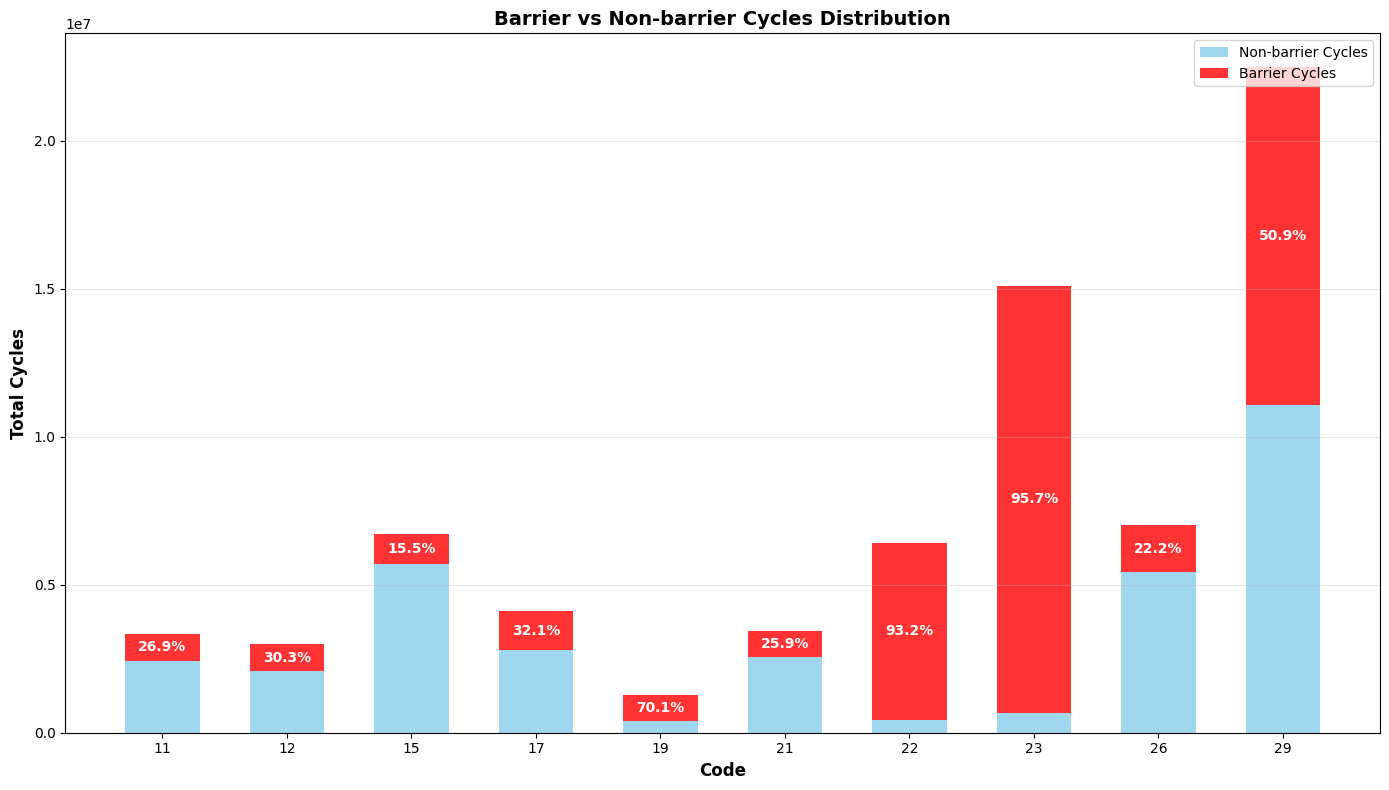

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from io import StringIO

# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

def create_sample_data():
   
    
    # 读取数据
    df = pd.read_csv('result.csv')
    
    # 处理空值
    barrier_columns = [col for col in df.columns if col.startswith('barrier_')]
    df[barrier_columns] = df[barrier_columns].fillna(0)
    
    return df

def calculate_barrier_ratios(df):
    """
    计算每行barrier列的总和以及占total_cycle的比例
    
    参数:
        df: DataFrame，包含code, total_cycle和barrier列
    
    返回:
        包含比例计算的DataFrame
    """
    # 识别barrier列
    barrier_columns = [col for col in df.columns if col.startswith('barrier_')]
    
    # 计算每行barrier的总和
    df['barrier_total'] = df[barrier_columns].sum(axis=1)
    
    # 计算barrier占total_cycle的比例
    df['barrier_ratio'] = df['barrier_total'] / df['total_cycle']
    
    # 计算非barrier部分的比例
    df['non_barrier_ratio'] = 1 - df['barrier_ratio']
    
    # 限制比例在0-1之间（防止数据异常）
    df['barrier_ratio'] = df['barrier_ratio'].clip(0, 1)
    df['non_barrier_ratio'] = df['non_barrier_ratio'].clip(0, 1)
    
    return df

def create_stacked_bar_chart(df, figsize=(12, 8)):
    """
    创建堆叠柱状图
    
    参数:
        df: 包含分析数据的DataFrame
        figsize: 图形大小
    """
    # 排序数据（按code排序）
    df_sorted = df.sort_values('code').reset_index(drop=True)
    
    # 创建图形
    fig, ax = plt.subplots(figsize=figsize)
    
    # 设置柱状图参数
    codes = df_sorted['code'].astype(str)
    total_cycles = df_sorted['total_cycle']
    barrier_ratios = df_sorted['barrier_ratio']
    non_barrier_ratios = df_sorted['non_barrier_ratio']
    
    # 计算柱状图的高度（实际的周期数）
    barrier_heights = total_cycles * barrier_ratios
    non_barrier_heights = total_cycles * non_barrier_ratios
    
    # 绘制堆叠柱状图
    width = 0.6
    x_pos = np.arange(len(codes))
    
    # 蓝色部分（非barrier）
    bars1 = ax.bar(x_pos, non_barrier_heights, width, 
                   label='Non-barrier Cycles', color='skyblue', alpha=0.8)
    
    # 红色部分（barrier）
    bars2 = ax.bar(x_pos, barrier_heights, width, 
                   bottom=non_barrier_heights, 
                   label='Barrier Cycles', color='red', alpha=0.8)
    
    # 设置图形属性
    ax.set_xlabel('Code', fontsize=12, fontweight='bold')
    ax.set_ylabel('Total Cycles', fontsize=12, fontweight='bold')
    ax.set_title('Barrier vs Non-barrier Cycles Distribution', fontsize=14, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(codes)
    
    # 添加图例
    ax.legend(loc='upper right')
    
    # 添加网格
    ax.grid(True, alpha=0.3, axis='y')
    
    # 在每个柱上添加比例标签
    for i, (code, barrier_ratio, total_cycle) in enumerate(zip(codes, barrier_ratios, total_cycles)):
        # 添加barrier比例标签
        if barrier_ratio > 0.05:  # 只在比例大于5%时显示
            ax.text(i, total_cycle * (1 - barrier_ratio/2), 
                   f'{barrier_ratio:.1%}', 
                   ha='center', va='center', fontweight='bold', color='white')
    
    # 调整布局
    plt.tight_layout()
    
    return fig, ax

def create_percentage_bar_chart(df, figsize=(12, 6)):
    """
    创建百分比柱状图（每个柱高度为100%）
    
    参数:
        df: 包含分析数据的DataFrame
        figsize: 图形大小
    """
    # 排序数据
    df_sorted = df.sort_values('code').reset_index(drop=True)
    
    # 创建图形
    fig, ax = plt.subplots(figsize=figsize)
    
    codes = df_sorted['code'].astype(str)
    barrier_ratios = df_sorted['barrier_ratio']
    non_barrier_ratios = df_sorted['non_barrier_ratio']
    
    # 绘制百分比堆叠柱状图
    width = 0.6
    x_pos = np.arange(len(codes))
    
    # 蓝色部分（非barrier）
    bars1 = ax.bar(x_pos, non_barrier_ratios, width, 
                   label='Non-barrier (%)', color='skyblue', alpha=0.8)
    
    # 红色部分（barrier）
    bars2 = ax.bar(x_pos, barrier_ratios, width, 
                   bottom=non_barrier_ratios, 
                   label='Barrier (%)', color='red', alpha=0.8)
    
    # 设置图形属性
    ax.set_xlabel('Code', fontsize=12, fontweight='bold')
    ax.set_ylabel('Percentage', fontsize=12, fontweight='bold')
    ax.set_title('Barrier vs Non-barrier Percentage Distribution', fontsize=14, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(codes)
    ax.set_ylim(0, 1)
    
    # 设置y轴为百分比格式
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
    
    # 添加图例
    ax.legend(loc='upper right')
    
    # 添加网格
    ax.grid(True, alpha=0.3, axis='y')
    
    # 在每个柱上添加具体百分比
    for i, (code, barrier_ratio) in enumerate(zip(codes, barrier_ratios)):
        if barrier_ratio > 0.05:  # 只在比例大于5%时显示
            ax.text(i, 1 - barrier_ratio/2, 
                   f'{barrier_ratio:.1%}', 
                   ha='center', va='center', fontweight='bold', color='white')
    
    plt.tight_layout()
    
    return fig, ax





def main():
    """
    主函数 - 执行完整的分析和可视化
    """
    print("=== Barrier数据分析和可视化 ===")
    
    # 1. 创建或加载数据
    df = create_sample_data()
    print(f"数据加载完成，共 {len(df)} 行")
    
    # 2. 计算barrier比例
    df = calculate_barrier_ratios(df)
    print("barrier比例计算完成")
    

    # 4. 创建可视化图表
    print("\n=== 生成可视化图表 ===")
    
    # 创建绝对数量的堆叠柱状图
    fig1, ax1 = create_stacked_bar_chart(df, figsize=(14, 8))
    fig1.savefig('barrier.png', dpi=300, bbox_inches='tight', 
                facecolor='white', edgecolor='none')
    print("图表已保存为: barrier.png")
    plt.show()
    
    # # 创建百分比堆叠柱状图
    # fig2, ax2 = create_percentage_bar_chart(df, figsize=(14, 6))
    # plt.show()
    
    
    return df


if __name__ == "__main__":
    # 运行主分析
    df_result = main()
    
    # 如果你有自己的CSV文件，可以这样分析：
    # df_custom = analyze_custom_data("your_data.csv")

In [104]:
import os
import glob
from pathlib import Path
import csv
import pandas as pd
import re
#
"""使用os.listdir遍历当前目录中包含'txt'的文件"""
df=create_initial_df()
for filename in os.listdir("."):
    if 'txt' in filename:
        numbers = re.findall(r'\d+', filename)
        new_row = pd.DataFrame({'code': [str(numbers[0])]})
        df = pd.concat([df, new_row], ignore_index=True)
        results,time_value = extract_time_from_txt_file(filename)
        df=add_column_to_df(df, "total_cycle", str(numbers[0]), time_value);
        meet_data,leave_data=find_syn_file(filename)
        
        df= calculate_barrier(meet_data,leave_data,df,results,str(numbers[0])); 
        print(filename+" is finsihed")     
df.to_csv('result.csv', index=False, encoding='utf-8')

创建了初始DataFrame，包含code列
22.txt is finsihed
15.txt is finsihed
23.txt is finsihed
11.txt is finsihed
29.txt is finsihed
12.txt is finsihed
17.txt is finsihed
21.txt is finsihed
19.txt is finsihed
26.txt is finsihed
